# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 12   # Вариант 12
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /home/anton/cv-2026-kucher/data
Вариант 12 уже на месте: /home/anton/cv-2026-kucher/data/variant_12


данные варианта: /home/anton/cv-2026-kucher/data/variant_12
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

786 фото, 4 породы: american_pit_bull_terrier, Bombay, Egyptian_Mau, staffordshire_bull_terrier
OpenCV 4.14.0 | numpy 2.5.4 | pandas 3.1.0


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [3]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

american_pit_bull_terrier_1.jpg (341, 512, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return {
        "mean_L": float(L.mean()),
        "std_L": float(L.std()),
        "noise_sigma": float(estimate_sigma(gray)),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
    }


In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,786.00,786.00,786.00,786.00,786.00,786.00
mean,418.47,373.37,118.11,59.83,1.18,504.23
std,211.73,198.71,33.85,15.57,1.20,722.39
min,114.00,103.00,18.41,22.04,0.00,7.35
25%,300.00,288.25,95.98,48.80,0.40,79.37
50%,400.00,352.00,116.91,59.10,0.76,257.93
75%,500.00,408.00,138.30,69.53,1.47,607.96
max,3264.00,2606.00,235.18,109.14,7.21,7285.78


In [6]:
# Средние четырёх чисел по породам
breed_stats = stats.groupby("breed")[["mean_L", "std_L", "noise_sigma", "sharpness"]].mean().round(2)
print("Средние четырёх чисел по породам:")
print(breed_stats)

darkest_breed = breed_stats["mean_L"].idxmin()
least_sharp_breed = breed_stats["sharpness"].idxmin()
print(f"\nСамая тёмная порода: {darkest_breed} (mean_L={breed_stats.loc[darkest_breed, 'mean_L']})")
print(f"Порода с наименьшей резкостью: {least_sharp_breed} (sharpness={breed_stats.loc[least_sharp_breed, 'sharpness']})")


Средние четырёх чисел по породам:
                            mean_L  std_L  noise_sigma  sharpness
breed                                                            
Bombay                      106.83  69.55         0.64     222.74
Egyptian_Mau                118.51  52.90         0.87     328.99
american_pit_bull_terrier   118.07  56.57         1.10     456.73
staffordshire_bull_terrier  129.55  60.15         2.14    1027.63

Самая тёмная порода: Bombay (mean_L=106.83)
Порода с наименьшей резкостью: Bombay (sharpness=222.74)


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

Самое тёмное: Bombay_191.jpg (mean_L=18.41)
Самое светлое: Egyptian_Mau_99.jpg (mean_L=235.18)


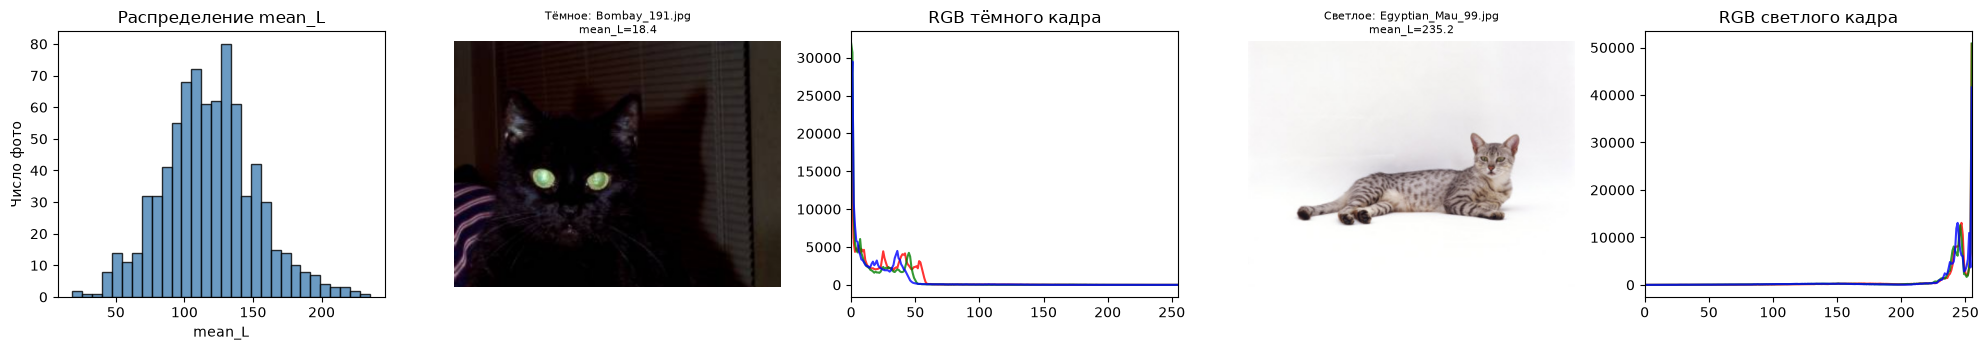

In [7]:
darkest_idx = stats["mean_L"].idxmin()
brightest_idx = stats["mean_L"].idxmax()
darkest_fn = stats.loc[darkest_idx, "filename"]
brightest_fn = stats.loc[brightest_idx, "filename"]

print(f"Самое тёмное: {darkest_fn} (mean_L={stats.loc[darkest_idx, 'mean_L']:.2f})")
print(f"Самое светлое: {brightest_fn} (mean_L={stats.loc[brightest_idx, 'mean_L']:.2f})")

darkest_rgb = load_rgb(darkest_fn)
brightest_rgb = load_rgb(brightest_fn)

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))

# 1. Гистограмма mean_L по варианту
axes[0].hist(stats["mean_L"], bins=30, color="steelblue", edgecolor="black", alpha=0.8)
axes[0].set_title("Распределение mean_L")
axes[0].set_xlabel("mean_L")
axes[0].set_ylabel("Число фото")

# 2. Тёмное фото
axes[1].imshow(darkest_rgb)
axes[1].set_title(f"Тёмное: {darkest_fn}\nmean_L={stats.loc[darkest_idx, 'mean_L']:.1f}", fontsize=8)
axes[1].axis("off")

# 3. Гистограмма каналов тёмного
for c, col in enumerate(["red", "green", "blue"]):
    hist = np.bincount(darkest_rgb[..., c].ravel(), minlength=256)
    axes[2].plot(hist, color=col, alpha=0.8)
axes[2].set_title("RGB тёмного кадра")
axes[2].set_xlim([0, 255])

# 4. Светлое фото
axes[3].imshow(brightest_rgb)
axes[3].set_title(f"Светлое: {brightest_fn}\nmean_L={stats.loc[brightest_idx, 'mean_L']:.1f}", fontsize=8)
axes[3].axis("off")

# 5. Гистограмма каналов светлого
for c, col in enumerate(["red", "green", "blue"]):
    hist = np.bincount(brightest_rgb[..., c].ravel(), minlength=256)
    axes[4].plot(hist, color=col, alpha=0.8)
axes[4].set_title("RGB светлого кадра")
axes[4].set_xlim([0, 255])

plt.tight_layout()
plt.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()


## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5   # можно подобрать своё значение


def correct(rgb, method):
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""
    if method == "eq_rgb":
        r, g, b = cv2.split(rgb)
        return cv2.merge([cv2.equalizeHist(r), cv2.equalizeHist(g), cv2.equalizeHist(b)])
    elif method == "eq_L":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        L, a, b = cv2.split(lab)
        L_eq = cv2.equalizeHist(L)
        return cv2.cvtColor(cv2.merge([L_eq, a, b]), cv2.COLOR_LAB2RGB)
    elif method == "clahe_L":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        L, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        L_clahe = clahe.apply(L)
        return cv2.cvtColor(cv2.merge([L_clahe, a, b]), cv2.COLOR_LAB2RGB)
    elif method == "gamma":
        lut = np.array([np.clip(255 * (i / 255.0) ** GAMMA, 0, 255) for i in range(256)], dtype=np.uint8)
        return cv2.LUT(rgb, lut)
    return rgb


Средние по методам коррекции:
          mean_L  std_L  color_shift
method                              
clahe_L    45.41  51.19         0.48
eq_L      139.46  62.63         0.19
eq_rgb    140.98  65.20        13.01
gamma      73.76  52.91         5.77
original   31.11  46.34         0.00


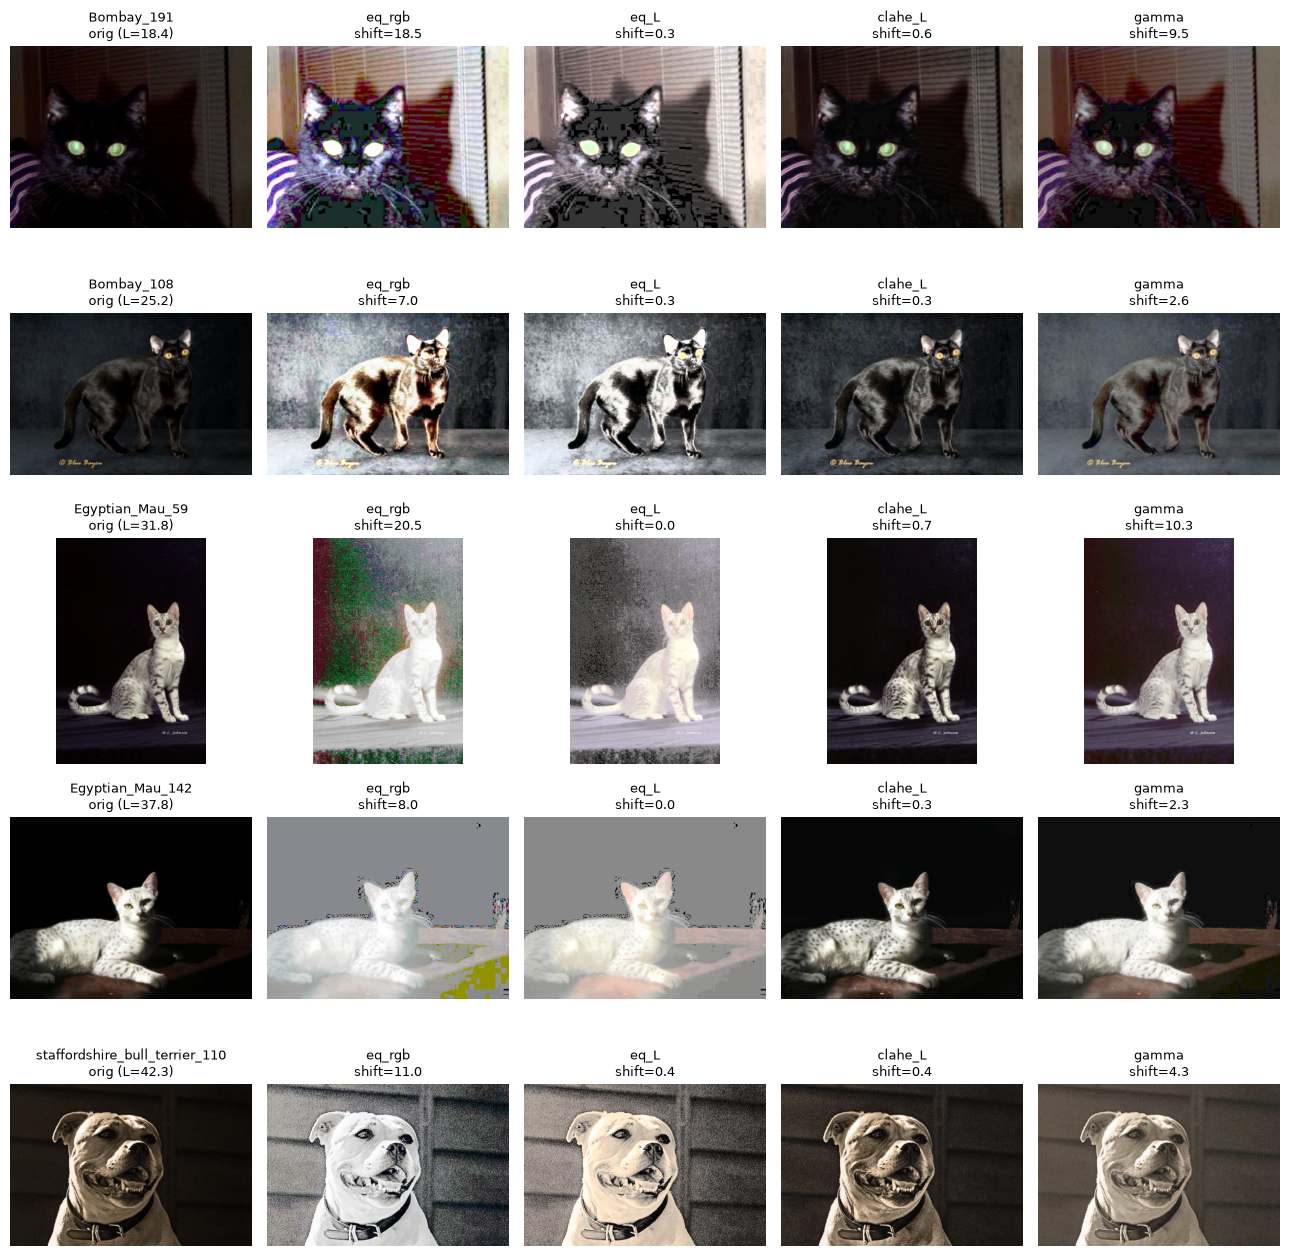

In [10]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]

top5_darkest = stats.nsmallest(5, "mean_L")
illum_rows = []
grid_images = []
grid_titles = []

for r in top5_darkest.itertuples():
    img_orig = load_rgb(r.filename)
    orig_L = cv2.cvtColor(img_orig, cv2.COLOR_RGB2LAB)[..., 0]
    illum_rows.append({
        "filename": r.filename,
        "method": "original",
        "mean_L": float(orig_L.mean()),
        "std_L": float(orig_L.std()),
        "color_shift": 0.0
    })
    grid_images.append(img_orig)
    grid_titles.append(f"{Path(r.filename).stem}\norig (L={orig_L.mean():.1f})")

    for m in METHODS:
        corr_img = correct(img_orig, m)
        corr_L = cv2.cvtColor(corr_img, cv2.COLOR_RGB2LAB)[..., 0]
        shift = color_shift(img_orig, corr_img)
        illum_rows.append({
            "filename": r.filename,
            "method": m,
            "mean_L": float(corr_L.mean()),
            "std_L": float(corr_L.std()),
            "color_shift": shift
        })
        grid_images.append(corr_img)
        grid_titles.append(f"{m}\nshift={shift:.1f}")

illum = pd.DataFrame(illum_rows)
print("Средние по методам коррекции:")
print(illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean().round(2))

show_grid(grid_images, grid_titles, ncols=5, path=RESULTS / "illumination.png", size=2.6)


## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

In [11]:
kernel = np.ones((3, 3), np.float32) / 9
f2d = cv2.filter2D(example, -1, kernel)
bl = cv2.blur(example, (3, 3))
diff = np.abs(f2d.astype(int) - bl.astype(int)).max()
print("Максимальная разность между cv2.filter2D и cv2.blur:", diff)
assert diff <= 1, "Фильтры должны совпадать с точностью до округления!"


Максимальная разность между cv2.filter2D и cv2.blur: 0


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=gauss sigma=15


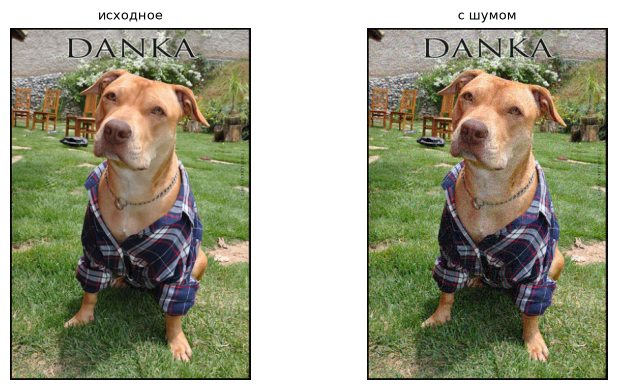

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
FILTERS = {
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),
    "gauss3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gauss5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gauss7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
}


In [15]:
def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""
    return {
        "psnr": float(cv2.PSNR(clean_img, out_img)),
        "ssim": float(structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)),
    }


In [16]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=gauss sigma=15,2.5980,31.9535,0.8622
blur3,kind=gauss sigma=15,0.1413,30.3162,0.8101
blur5,kind=gauss sigma=15,0.1596,28.9070,0.7894
blur7,kind=gauss sigma=15,0.2804,27.2853,0.7361
gauss3,kind=gauss sigma=15,0.1088,30.6966,0.8081
gauss5,kind=gauss sigma=15,0.1416,30.5957,0.8348
gauss7,kind=gauss sigma=15,0.1529,29.7166,0.8240
median3,kind=gauss sigma=15,0.1000,29.7997,0.7643
median5,kind=gauss sigma=15,0.5953,29.5292,0.7812


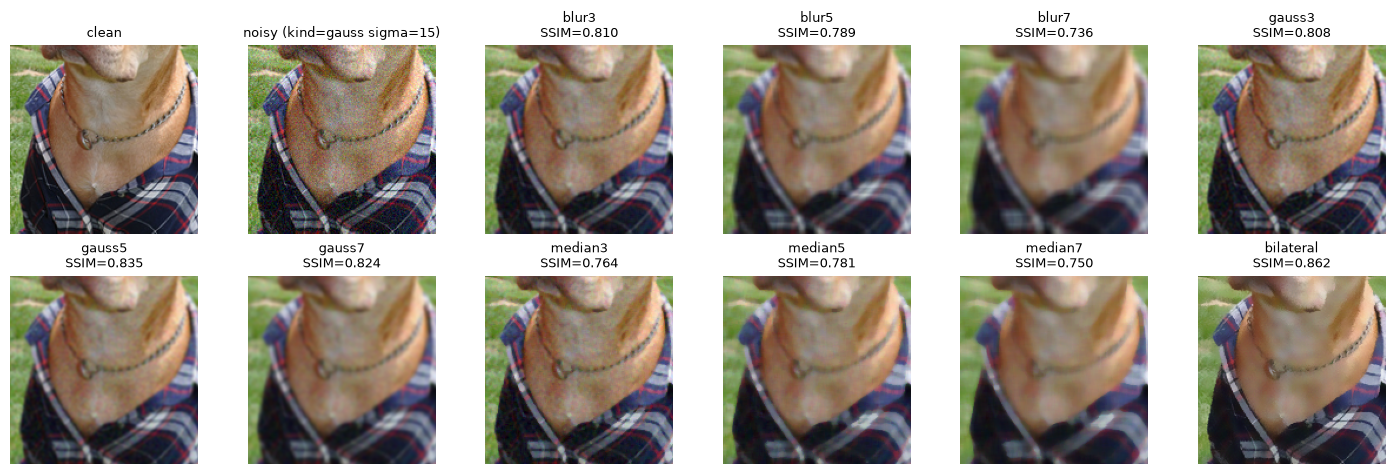

In [17]:
H, W = clean[0].shape[:2]
cy, cx = H // 2, W // 2
crop_slice = (slice(cy - 80, cy + 80), slice(cx - 80, cx + 80))

crops = [clean[0][crop_slice], noisy[0][crop_slice]]
titles = ["clean", f"noisy ({NOISE_NAME})"]

for name, f in FILTERS.items():
    filtered = f(noisy[0])
    crops.append(filtered[crop_slice])
    ssim_val = filt_summary.loc[name, "ssim"]
    titles.append(f"{name}\nSSIM={ssim_val:.3f}")

show_grid(crops, titles, ncols=6, path=RESULTS / "filters.png", size=2.4)


In [18]:
print(filt_summary.sort_values("ssim", ascending=False))
BEST_FILTER = "bilateral"   # Победитель по PSNR и SSIM
print("Выбран лучший фильтр:", BEST_FILTER)


                         noise       ms     psnr    ssim
filter                                                  
bilateral  kind=gauss sigma=15   2.5980  31.9535  0.8622
gauss5     kind=gauss sigma=15   0.1416  30.5957  0.8348
gauss7     kind=gauss sigma=15   0.1529  29.7166  0.8240
blur3      kind=gauss sigma=15   0.1413  30.3162  0.8101
gauss3     kind=gauss sigma=15   0.1088  30.6966  0.8081
blur5      kind=gauss sigma=15   0.1596  28.9070  0.7894
median5    kind=gauss sigma=15   0.5953  29.5292  0.7812
median3    kind=gauss sigma=15   0.1000  29.7997  0.7643
median7    kind=gauss sigma=15  11.1365  28.4671  0.7497
blur7      kind=gauss sigma=15   0.2804  27.2853  0.7361
none       kind=gauss sigma=15   0.0013  24.9898  0.5179
Выбран лучший фильтр: bilateral


**Почему выбран этот фильтр.**
Для гауссова шума ($\sigma = 15$) безоговорочным победителем стал `bilateral` (билатеральный фильтр): он показал наивысшие значения как по метрике PSNR (31.95 дБ против 30.60 дБ у ближайшего `gauss5`), так и по SSIM (0.862 против 0.835 у `gauss5`). В отличие от обычного размытия по Гауссу, билатеральная фильтрация учитывает не только геометрическое расстояние между пикселями, но и фотометрическую разность интенсивностей, эффективно сглаживая шум на однородных участках и одновременно сохраняя резкие границы и текстуру шерсти. Платой за это является время работы (~2.8 мс на кадр против ~0.2 мс у GaussianBlur), однако в рамках покадровой обработки эта задержка несущественна.


# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [20]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

american_pit_bull_terrier_12.jpg (512, 350, 3) значения trimap: [1 2 3]


Найденный порог Оцу: t = 103.0, IoU = 0.148
После исправления полярности: IoU = 0.053
После морфологии (open=7, close=31): IoU = 0.085
После заливки дыр и связной компоненты: IoU = 0.077
Адаптивный порог: IoU = 0.124


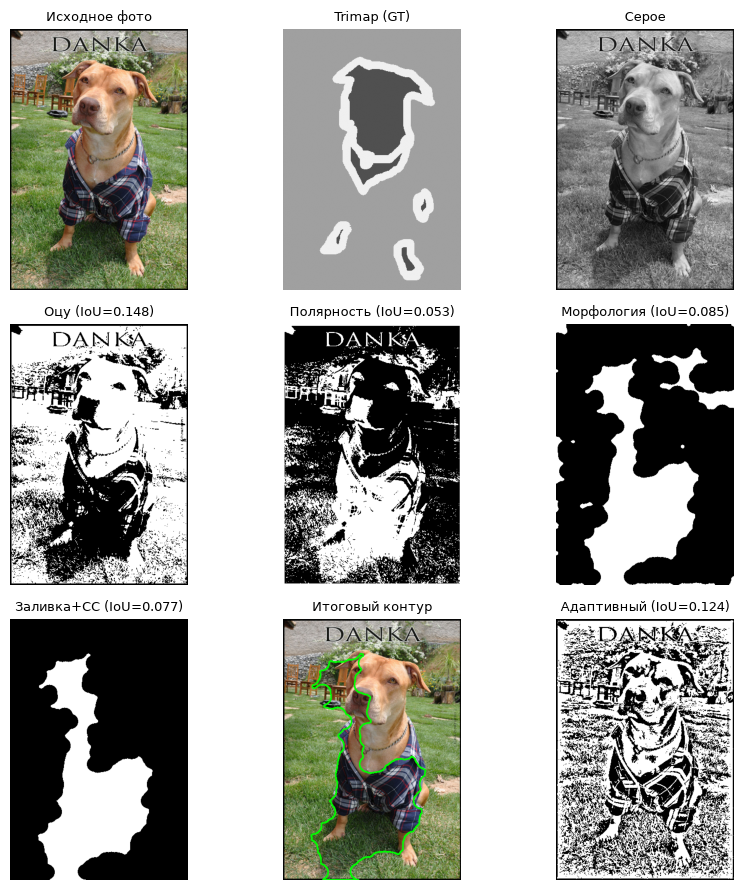

In [21]:
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

# 1. Оцу
t, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Найденный порог Оцу: t = {t:.1f}, IoU = {iou_ignore(otsu, tri):.3f}")

# 2. Полярность
border_mask = np.zeros_like(otsu, dtype=bool)
border_mask[:10, :] = True
border_mask[-10:, :] = True
border_mask[:, :10] = True
border_mask[:, -10:] = True
pol = cv2.bitwise_not(otsu) if np.mean(otsu[border_mask] == 255) > 0.5 else otsu.copy()
print(f"После исправления полярности: IoU = {iou_ignore(pol, tri):.3f}")

# 3. Морфология
k_open, k_close = 7, 31
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close))
m_open = cv2.morphologyEx(pol, cv2.MORPH_OPEN, kernel_open)
m_close = cv2.morphologyEx(m_open, cv2.MORPH_CLOSE, kernel_close)
print(f"После морфологии (open={k_open}, close={k_close}): IoU = {iou_ignore(m_close, tri):.3f}")

# 4. Заливка дыр и выбор самой большой компоненты
pad = cv2.copyMakeBorder(m_close, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
flood = pad.copy()
h_p, w_p = flood.shape
flood_mask = np.zeros((h_p + 2, w_p + 2), np.uint8)
cv2.floodFill(flood, flood_mask, (0, 0), 255)
crop = flood[1:-1, 1:-1]
filled = m_close | cv2.bitwise_not(crop)

num_labels, labels_im, stats_cc, centroids = cv2.connectedComponentsWithStats(filled)
if num_labels > 1:
    largest_label = 1 + np.argmax(stats_cc[1:, cv2.CC_STAT_AREA])
    comp = (labels_im == largest_label).astype(np.uint8) * 255
else:
    comp = np.zeros_like(filled)
print(f"После заливки дыр и связной компоненты: IoU = {iou_ignore(comp, tri):.3f}")

# 5. Контур на фото
contours, _ = cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
rgb_contour = rgb.copy()
cv2.drawContours(rgb_contour, contours, -1, (0, 255, 0), 2)

# 6. Адаптивный порог для сравнения
adapt = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)
print(f"Адаптивный порог: IoU = {iou_ignore(adapt, tri):.3f}")

panels = [
    rgb,
    tri * 80,
    gray,
    otsu,
    pol,
    m_close,
    comp,
    rgb_contour,
    adapt
]
titles = [
    "Исходное фото",
    "Trimap (GT)",
    "Серое",
    f"Оцу (IoU={iou_ignore(otsu, tri):.3f})",
    f"Полярность (IoU={iou_ignore(pol, tri):.3f})",
    f"Морфология (IoU={iou_ignore(m_close, tri):.3f})",
    f"Заливка+CC (IoU={iou_ignore(comp, tri):.3f})",
    "Итоговый контур",
    f"Адаптивный (IoU={iou_ignore(adapt, tri):.3f})"
]

show_grid(panels, titles, ncols=3, path=RESULTS / "pipeline.png", size=3.0)


## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [22]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    """Маска животного (bool, размер как у rgb)."""
    img = rgb
    if smooth and BEST_FILTER is not None and BEST_FILTER in FILTERS:
        img = FILTERS[BEST_FILTER](img)

    x = CHANNELS[channel](img)
    t, mask = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if polarity:
        border_mask = np.zeros_like(mask, dtype=bool)
        border_mask[:10, :] = True
        border_mask[-10:, :] = True
        border_mask[:, :10] = True
        border_mask[:, -10:] = True
        if np.mean(mask[border_mask] == 255) > 0.5:
            mask = cv2.bitwise_not(mask)

    if morph:
        kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
        kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)

    if fill:
        pad = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
        flood = pad.copy()
        h_p, w_p = flood.shape
        f_mask = np.zeros((h_p + 2, w_p + 2), np.uint8)
        cv2.floodFill(flood, f_mask, (0, 0), 255)
        crop = flood[1:-1, 1:-1]
        mask = mask | cv2.bitwise_not(crop)

        num_labels, labels_im, stats_cc, centroids = cv2.connectedComponentsWithStats(mask)
        if num_labels > 1:
            largest_label = 1 + np.argmax(stats_cc[1:, cv2.CC_STAT_AREA])
            mask = (labels_im == largest_label).astype(np.uint8) * 255
        else:
            mask = np.zeros_like(mask)

    return mask > 0


In [23]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [24]:
# Сравнение каналов на выборке изображений
ch_eval = evaluate({
    "gray": dict(channel="gray"),
    "S": dict(channel="S"),
    "a": dict(channel="a"),
    "b": dict(channel="b"),
})
print("Сравнение каналов по IoU:")
print(summarize(ch_eval))

CHANNEL = "gray"   # Канал-победитель
print("Выбран канал:", CHANNEL)


Сравнение каналов по IoU:
      mean_iou  median_iou
gray     0.498       0.489
S        0.436       0.405
a        0.357       0.258
b        0.393       0.313
Выбран канал: gray


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [25]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: bilateral


,mean_iou,median_iou
1 только Оцу,0.191,0.099
2 + фильтр из части 1,0.192,0.095
3 + полярность,0.444,0.414
4 + морфология,0.477,0.456
5 + заливка и компонента,0.498,0.489


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [26]:
def shape_features(mask):
    """Признаки формы маски: area_frac, perimeter, x, y, w, h, elongation, circularity, solidity."""
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return {
            "area_frac": 0.0, "perimeter": 0.0, "x": 0, "y": 0, "w": 0, "h": 0,
            "elongation": 0.0, "circularity": 0.0, "solidity": 0.0
        }
    c = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(c)
    total_area = mask.shape[0] * mask.shape[1]
    area_frac = float(area / total_area) if total_area > 0 else 0.0
    perimeter = float(cv2.arcLength(c, True))
    x, y, w, h = cv2.boundingRect(c)
    
    rect = cv2.minAreaRect(c)
    rw, rh = rect[1]
    elongation = float(max(rw, rh) / min(rw, rh)) if min(rw, rh) > 0 else 1.0
    
    circularity = float(4 * np.pi * area / (perimeter ** 2)) if perimeter > 0 else 0.0
    hull = cv2.convexHull(c)
    hull_area = cv2.contourArea(hull)
    solidity = float(area / hull_area) if hull_area > 0 else 0.0
    
    return {
        "area_frac": area_frac,
        "perimeter": perimeter,
        "x": int(x),
        "y": int(y),
        "w": int(w),
        "h": int(h),
        "elongation": elongation,
        "circularity": circularity,
        "solidity": solidity,
    }


In [27]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,american_pit_bull_terrier_1.jpg,american_pit_bull_terrier,dog,0.356514,0.258440,1299.383900,108,46,270,295,1.271318,0.335829,0.757581
1,american_pit_bull_terrier_2.jpg,american_pit_bull_terrier,dog,0.510084,0.375361,2005.876321,0,0,427,341,1.252941,0.204680,0.643803
2,american_pit_bull_terrier_4.jpg,american_pit_bull_terrier,dog,0.579254,0.318851,2651.329200,1,0,511,321,1.687490,0.099224,0.423892
3,american_pit_bull_terrier_5.jpg,american_pit_bull_terrier,dog,0.034153,0.233516,2132.660154,19,0,486,236,2.082562,0.166819,0.646975
4,american_pit_bull_terrier_6.jpg,american_pit_bull_terrier,dog,0.986271,0.191040,1036.097541,0,76,242,308,1.273859,0.439677,0.808559


In [28]:
breed_shape_summary = masks.groupby("breed")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean().round(3)
print("Сводка признаков формы и IoU по породам:")
print(breed_shape_summary)

species_shape_summary = masks.groupby("species")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean().round(3)
print("\nСводка по видам (кошки vs собаки):")
print(species_shape_summary)


Сводка признаков формы и IoU по породам:
                              iou  area_frac  elongation  circularity  \
breed                                                                   
Bombay                      0.575      0.426       1.518        0.355   
Egyptian_Mau                0.543      0.397       1.477        0.269   
american_pit_bull_terrier   0.434      0.418       1.435        0.288   
staffordshire_bull_terrier  0.439      0.435       1.467        0.288   

                            solidity  
breed                                 
Bombay                         0.742  
Egyptian_Mau                   0.675  
american_pit_bull_terrier      0.702  
staffordshire_bull_terrier     0.715  

Сводка по видам (кошки vs собаки):
           iou  area_frac  elongation  circularity  solidity
species                                                     
cat      0.559      0.412       1.498        0.313     0.709
dog      0.436      0.426       1.451        0.288     0.708


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

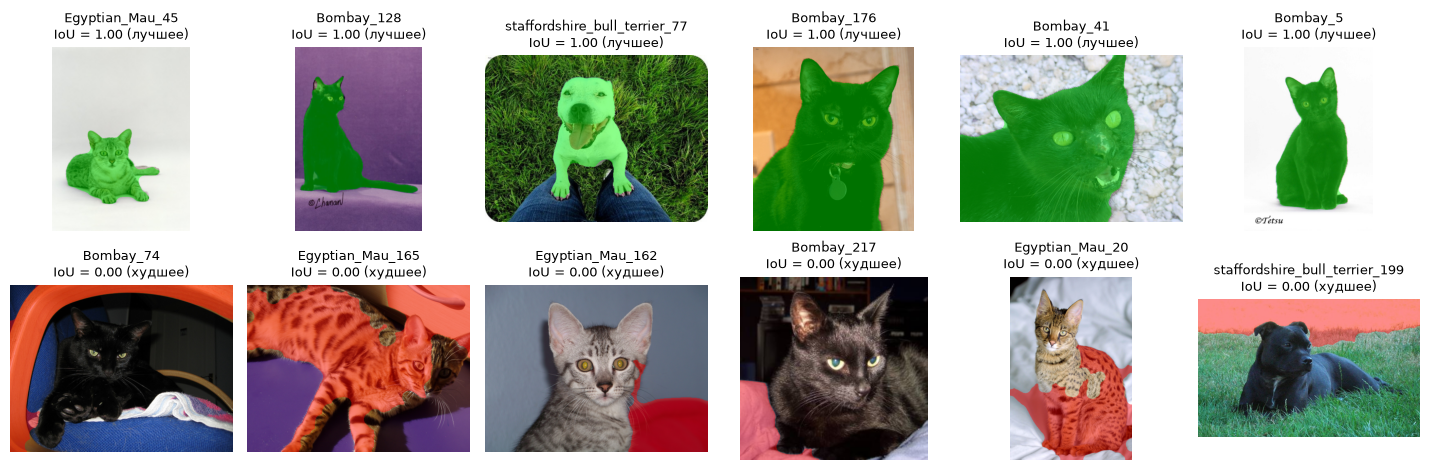

In [29]:
ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
best_6 = ranked.head(6)
worst_6 = ranked.tail(6)

panels = []
titles = []

for r in best_6.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    panels.append(overlay(rgb, mask))
    titles.append(f"{Path(r.filename).stem}\nIoU = {r.iou:.2f} (лучшее)")

for r in worst_6.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    panels.append(overlay(rgb, mask, color=(255, 0, 0)))
    titles.append(f"{Path(r.filename).stem}\nIoU = {r.iou:.2f} (худшее)")

show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.4)


## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [30]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 12 | шум kind=gauss sigma=15 | BEST_FILTER = bilateral | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [31]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)